# 에이전트 흐름도 (LangGraph)

세린님 최종 체인의 에이전트에 **청크 복구 노드**를 더한 에이전트(카드 015)의 흐름을 LangGraph에서 직접 꺼내 그림으로 봅니다.

- 그림은 LangGraph가 컴파일한 그래프(`graph.get_graph()`)에서 만들고, 노드와 분기 이름만 한글로 바꿉니다. 코드에서 노드를 바꾸면 그림도 같이 바뀝니다.
- 에이전트 코드는 같은 저장소의 `src/rag/agent_repair.py`(복구)와 `src/rag/agent.py`(세린님 T3)이고, 이 노트북은 같은 폴더의 `agent.py`를 통해 불러옵니다.
- 처음 한 번은 인덱스가 필요합니다: `python scripts/build_index.py --config configs/015-context-repair.yaml` (임베딩 약 0.15 USD)
- 1~3번 셀은 API를 쓰지 않습니다. 4번 셀만 실제 질문을 실행합니다(LLM 4~6회, 약 0.01~0.02 USD).
- 그림은 mermaid.ink 웹 서비스로 그립니다. 인터넷이 안 되면 같은 그림을 브라우저용 HTML로 보여 줍니다.

In [1]:
# 1. 준비: 에이전트 불러오기 + 그림 그리는 함수
from IPython.display import HTML, Image, Markdown, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

import agent as A   # 같은 폴더의 agent.py

repair, cfg = A.load_agent("repair")   # 카드 015 복구 에이전트
t3, _ = A.load_agent("t3")             # 세린님 T3 에이전트 (비교용)


def show(mermaid: str):
    try:
        display(Image(draw_mermaid_png(mermaid)))
    except Exception as e:  # 인터넷이 안 될 때: 브라우저에서 mermaid.js로 그림
        print("mermaid.ink 를 쓸 수 없어 HTML로 그립니다:", type(e).__name__)
        display(HTML('<pre class="mermaid">' + mermaid.replace("<", "&lt;").replace("&lt;br>", "<br>") + "</pre>"
                     '<script type="module">import m from "https://cdn.jsdelivr.net/npm/mermaid@11.4.1/dist/mermaid.esm.min.mjs";'
                     "m.initialize({startOnLoad:false}); m.run();</script>"))

print("불러온 설정:", cfg["name"], "|", cfg["description"])

불러온 설정: 015_context_repair | T3 agent with context repair: diagnose (cut / not_found / garbled) -> expand cut chunks to the page and re-check, re-search, or flag the page (card 015)


## 2. 복구 에이전트 흐름도

| 노드 | 하는 일 | LLM |
|---|---|---|
| 질문 유형 분류 | 문서로 답할 질문인지, 질문자 정보가 더 필요한지, 부적절한 요청인지, 지시문이 섞였는지 나눕니다 | 1회 |
| 문서 검색 | 하이브리드 검색으로 15개를 찾고 LLM이 5개로 다시 고릅니다 (세린님 최종 체인과 같음) | 1회 |
| 근거 진단 | 근거가 충분한지, 부족하면 **왜** 부족한지(청크가 잘림 / 다른 근거가 필요 / 글자가 깨짐) 판단합니다 | 1회 |
| 잘린 청크를 페이지 전체로 확장 | 잘린 청크를 그 페이지 전체 글로 바꾸고 **다시 근거 진단**으로 돌아갑니다 (질문당 1회, 최대 3페이지) | 0 |
| 검색어 다시 쓰기 | 빠진 정보를 찾을 새 검색어를 만들어 다시 검색합니다 (최대 2회) | 1회 |
| 깨진 페이지 기록 | 깨진 페이지를 기록해 두고(나중에 다시 추출) 남은 근거로 답변으로 넘어갑니다 | 0 |
| 답변 작성 | 세린님 최종 체인과 같은 답변 프롬프트로 답하고 답변 / 보류 / 되묻기 / 거절 중 하나를 고릅니다 | 1회 |
| 인용 번호 확인 | 인용 번호가 검색 결과 안에 있는지 코드로 확인하고, 틀리면 한 번 다시 씁니다 | 0 |

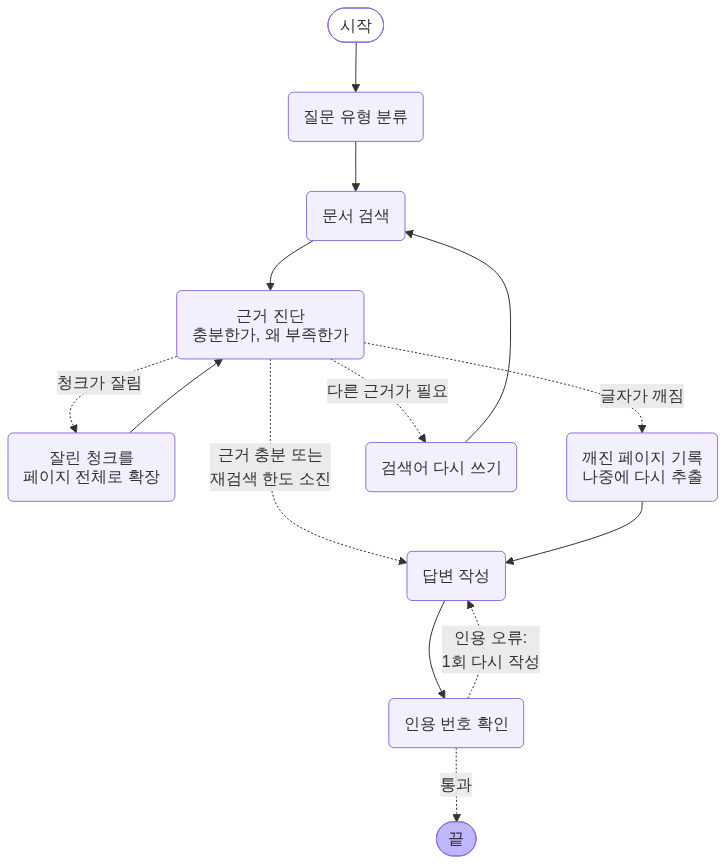

In [2]:
# 2. 복구 에이전트 (카드 015) 흐름도
show(A.korean_mermaid(repair))

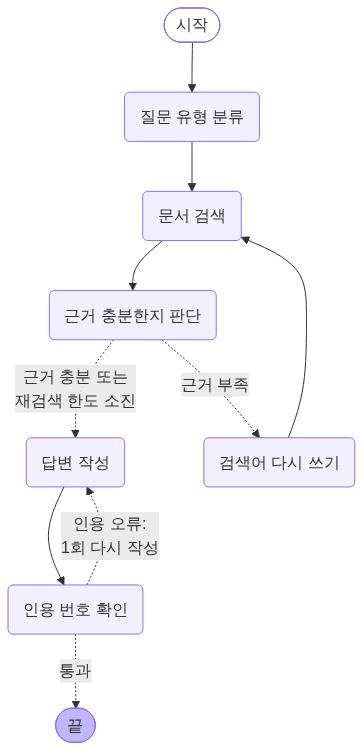

In [3]:
# 3. 비교: 세린님 T3 에이전트 흐름도 (복구 노드 없음)
show(A.korean_mermaid(t3))

## 4. 질문 하나 실행해서 지나간 길 보기

- `QID`에 dev 골드셋 문항 ID를 넣으면 정답 페이지와 비교까지 보여 줍니다. 직접 쓴 질문을 넣으려면 `QUESTION`에 쓰고 `SCOPE`를 고릅니다(A: 용어집+약관, B: 전체 23개 PDF).
- 노란색 노드가 이번 질문이 실제로 지나간 노드입니다. 근거 진단은 LLM이 판단하므로 실행마다 길이 달라질 수 있습니다.

[질문] 집값이 많이 올라서 해지하고 같은 집으로 바로 다시 가입하면 더 받을 것 같아요. 나중에 제가 죽으면 자녀가 받은 연금 부족분까지 갚아야 하나요? 자녀가 현금으로 정리하고 집을 남기는 것도 가능한가요?

[진행 과정]
1. 질문 유형 분류: 문서로 답할 질문
   → 문서 검색: "집값이 많이 올라서 해지하고 같은 집으로 바로 다시 가입하면 더 받을 것…" → 청크 5개
2. 근거 판단: 충분
3. 답변 작성 → 인용 확인: 통과

[지나간 노드] 시작 → 질문 유형 분류 → 문서 검색 → 근거 진단 → 답변 작성 → 인용 번호 확인 → 끝

[결과] 답변
질문하신 내용을 세 부분으로 나누어 설명해 드립니다.

1. 해지 후 같은 집으로 즉시 재가입 여부
주택연금을 중도 해지하는 경우 원칙적으로 해지일로부터 3년 동안은 동일한 주택을 담보로 다시 가입할 수 없습니다 [1]. 다만, 재가입 시점의 주택가격(평가액)이 직전 가입 시점의 주택가격(평가액)에 직전 가입 시점의 연금모형상 주택가격상승률을 적용한 가액 이하[재가입 시 주택가격 ≤ 당초 주택가격 × (1 + 주택가격상승률/12)ᵗ, (t는 경과 월 수)]인 경우에만 재가입이 가능합니다 [1], [3]. 따라서 집값이 많이 올랐다면 해지 후 바로 동일주택으로 재가입하는 것은 불가능합니다 [1], [3].

2. 사망 시 자녀의 연금 부족분 상환 의무
주택연금은 주택처분가액으로 대출금을 상환하고 부족한 금액이 생기더라도 상속인이나 다른 재산에 청구하지 않는 비소구 대출입니다 [2]. 부부가 모두 사망한 후 대출잔액이 담보주택 가격보다 많더라도 부족금액을 자녀에게 별도로 청구하거나 상환하도록 요구하지 않습니다 [2].

3. 자녀가 현금으로 정산하고 집을 남기는 것의 가능 여부
가능합니다. 부부가 모두 사망 시 상속인은 직접 현금 상환을 통해 우선적으로 대출금을 정리할 수 있으며, 이 경우 주택을 처분하지 않고 남길 수 있습니다 [1]. 상속인이 상환 의사가 없거나 정산을 거부할 때만 민법 및 민사집행

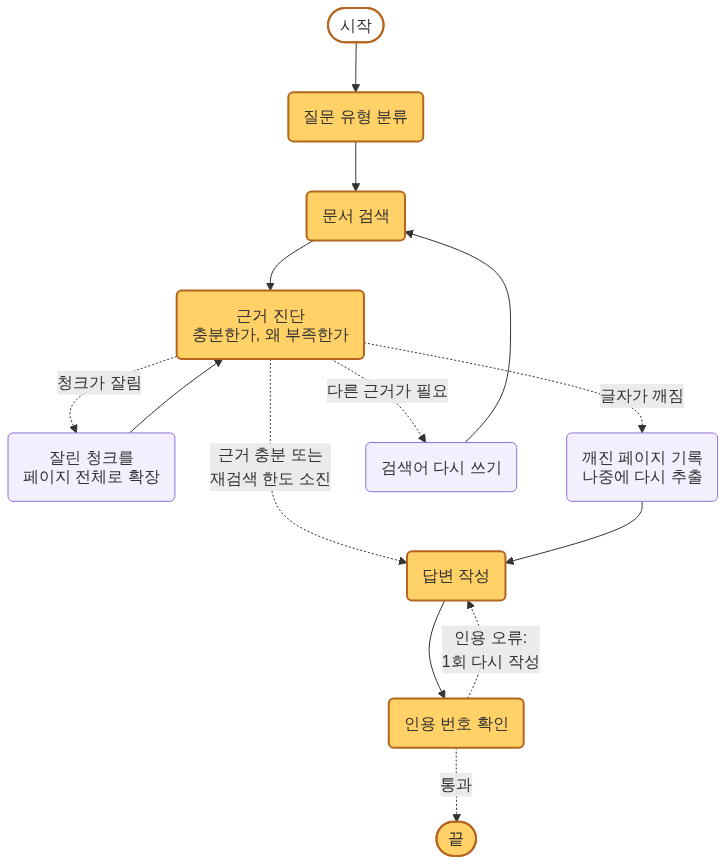

In [4]:
# 4. 실행 (API 사용)
QID = "ADD-HP09"      # 예: "POS001", "ADD-SE06" / 직접 쓴 질문을 쓰려면 None
QUESTION = None       # 예: "주택연금은 몇 살부터 가입할 수 있나요?"
SCOPE = "B"

from rag.golden import scope_of
item = A.dev_item(QID) if QID else None
question, scope = (item["question"], scope_of(item, cfg)) if item else (QUESTION, SCOPE)

result = A.run_question(repair, cfg, question, scope)
print("[질문]", question)
print(A.report(result, item))
show(A.korean_mermaid(repair, path=A.visited_path(result["steps"])))